# Khám phá dữ liệu giao dịch gian lận (EDA)

Notebook này hướng dẫn từng bước khám phá dữ liệu trong project. Chạy các ô theo thứ tự từ trên xuống bằng nút **Run** hoặc **Shift+Enter**. Ô có biểu tượng `In [ ]` là ô chưa chạy.

**Mục tiêu:** hiểu cấu trúc dữ liệu, phân phối nhãn `is_fraud`, mối liên hệ giữa đặc trưng và fraud, giá trị bất thường, khác biệt train/test và đề xuất validation. Notebook chỉ đọc dữ liệu gốc; không huấn luyện mô hình và không sửa CSV.

> Nếu chạy notebook từ thư mục `notebooks`, các đường dẫn bên dưới sẽ tự tìm thư mục gốc project.

## 1. Chuẩn bị và đọc dữ liệu

Ô tiếp theo nạp các thư viện, tìm thư mục project, rồi đọc train/test. Nếu thiếu thư viện, mở Terminal ở thư mục project, kích hoạt môi trường `.venv` và chạy `python -m pip install -r requirements.txt`.

In [23]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

# Tự tìm thư mục gốc từ thư mục hiện tại hoặc thư mục notebooks.
def find_project_root(start=Path.cwd()):
    for folder in [start, *start.parents]:
        if (folder / 'datasets' / 'raw' / 'train.csv').exists():
            return folder
    raise FileNotFoundError('Không tìm thấy datasets/raw/train.csv. Hãy mở notebook trong project này.')

ROOT = find_project_root()
TRAIN_PATH = ROOT / 'datasets' / 'raw' / 'train.csv'
TEST_PATH = ROOT / 'datasets' / 'raw' / 'test.csv'
TARGET = 'is_fraud'
ID_COLUMN = 'id'
SEED = 42  # Seed gợi ý trong hướng dẫn; validation chính thức cần nhóm thống nhất.

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print(f'Thư mục project: {ROOT}')
print(f'Train: {train.shape[0]:,} dòng × {train.shape[1]} cột')
print(f'Test:  {test.shape[0]:,} dòng × {test.shape[1]} cột')
print(f'Python: {sys.version.split()[0]} | pandas: {pd.__version__} | NumPy: {np.__version__}')

Thư mục project: c:\Users\thaid\Downloads\predicting-credit-card-fraud
Train: 699,960 dòng × 26 cột
Test:  299,984 dòng × 25 cột
Python: 3.14.6 | pandas: 3.1.1 | NumPy: 2.5.5


## 2. Kiểm tra nhanh cấu trúc

Ta kiểm tra cột, kiểu dữ liệu, giá trị thiếu, ID trùng và nhãn hợp lệ. Nếu có lỗi `AssertionError`, hãy dừng lại và so sánh với `docs/01_DATA_AUDIT.md` trước khi phân tích tiếp.

In [24]:
print('Các cột train:')
display(pd.DataFrame({'cột': train.columns, 'kiểu dữ liệu': train.dtypes.astype(str).values}))

assert TARGET in train.columns, f'Train phải có cột {TARGET}'
assert TARGET not in test.columns, f'Test không nên có cột {TARGET}'
assert ID_COLUMN in train.columns and ID_COLUMN in test.columns
assert set(train[TARGET].dropna().unique()).issubset({0, 1}), 'Target có giá trị ngoài 0/1'
assert list(train.drop(columns=TARGET).columns) == list(test.columns), 'Schema/cột train và test không khớp'

quality = pd.DataFrame({
    'train_missing': train.isna().sum(),
    'test_missing': test.reindex(columns=train.drop(columns=TARGET).columns).isna().sum(),
    'train_unique': train.nunique(dropna=False),
    'test_unique': test.reindex(columns=train.drop(columns=TARGET).columns).nunique(dropna=False),
})
display(quality)
print('Dòng trùng hoàn toàn train:', int(train.duplicated().sum()))
print('ID trùng train/test:', len(set(train[ID_COLUMN]) & set(test[ID_COLUMN])))

Các cột train:


,cột,kiểu dữ liệu
0,id,int64
1,amount_usd,float64
2,hours_since_last_txn,float64
3,txn_count_last_24h,int64
4,distance_from_home_km,float64
5,card_age_months,int64
6,customer_age,int64
7,account_balance_usd,float64
8,cvv_retry_count,int64
9,velocity_score,float64


,train_missing,test_missing,train_unique,test_unique
account_balance_usd,0,0.0,43317,31803.0
amount_usd,0,0.0,13387,10510.0
auth_method,0,0.0,5,5.0
billing_shipping_mismatch,0,0.0,2,2.0
card_age_months,0,0.0,49,49.0
card_type,0,0.0,5,5.0
channel,0,0.0,5,5.0
customer_age,0,0.0,64,64.0
cvv_retry_count,0,0.0,4,4.0
day_of_week,0,0.0,7,7.0


Dòng trùng hoàn toàn train: 0
ID trùng train/test: 0


## 3. Nhãn fraud và mức mất cân bằng

Fraud thường hiếm. Hãy nhìn cả số lượng và phần trăm của mỗi lớp. Vì vậy accuracy không nên là thước đo chính ở các bước mô hình sau này; hướng dẫn project đề xuất ROC-AUC và PR-AUC.

,số giao dịch,tỷ lệ (%)
Không fraud (0),688271,98.330047
Fraud (1),11689,1.669953


Tỷ lệ fraud: 1.6700%
Tỷ lệ non-fraud / fraud: 58.9 : 1


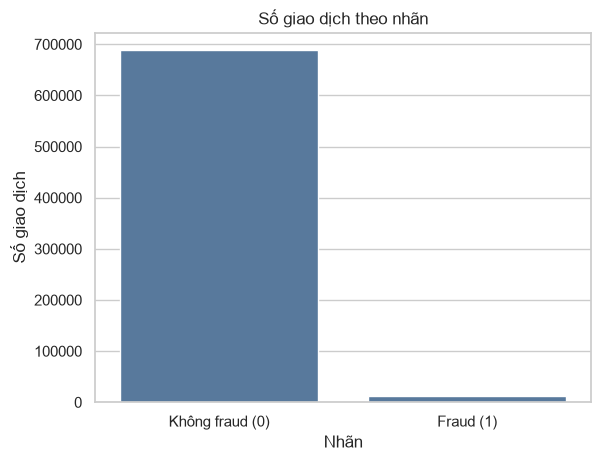

In [25]:
target_counts = train[TARGET].value_counts().sort_index()
target_summary = pd.DataFrame({'số giao dịch': target_counts, 'tỷ lệ (%)': target_counts / len(train) * 100})
target_summary.index = ['Không fraud (0)' if x == 0 else 'Fraud (1)' for x in target_summary.index]
display(target_summary)
fraud_rate = train[TARGET].mean()
print(f'Tỷ lệ fraud: {fraud_rate:.4%}')
print(f'Tỷ lệ non-fraud / fraud: {(1-fraud_rate)/fraud_rate:.1f} : 1')

ax = sns.barplot(x=target_summary.index, y=target_summary['số giao dịch'].values, color='#4C78A8')
ax.set(title='Số giao dịch theo nhãn', xlabel='Nhãn', ylabel='Số giao dịch')
plt.show()

## 4. Chia nhóm đặc trưng

`id` là mã định danh nên mặc định không đưa vào đặc trưng dự đoán. Các cột số nguyên nhỏ như giờ/ngày vẫn cần được hiểu theo ý nghĩa của chúng, không phải lúc nào cũng là đại lượng liên tục.

In [26]:
FEATURES = [c for c in train.columns if c not in [TARGET, ID_COLUMN]]
numeric_features = [c for c in FEATURES if pd.api.types.is_numeric_dtype(train[c]) and not pd.api.types.is_bool_dtype(train[c])]
categorical_features = [
    c for c in FEATURES
    if pd.api.types.is_string_dtype(train[c])
    or pd.api.types.is_object_dtype(train[c])
]
binary_features = [c for c in FEATURES if pd.api.types.is_bool_dtype(train[c])]
print('Biến số:', numeric_features)
print('Biến phân loại:', categorical_features)
print('Biến đúng/sai:', binary_features)
print('Số đặc trưng, không tính id và target:', len(FEATURES))

Biến số: ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']
Biến phân loại: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
Biến đúng/sai: ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
Số đặc trưng, không tính id và target: 24


## 5. Phân tích biến số

Bảng dưới đây tóm tắt các thống kê chính. Histogram giúp nhận ra hình dạng phân phối; boxplot giúp nhìn phần đuôi. Biểu đồ chỉ gợi ý điều cần điều tra, không chứng minh nguyên nhân. Để dễ đọc, phần biểu đồ fraud/non-fraud lấy mẫu ngẫu nhiên tối đa 50.000 dòng; bảng thống kê vẫn dùng toàn bộ dữ liệu.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,n_unique,skew
amount_usd,699960.0,79.893068,205.173538,1.00,4.42,6.86,15.81,27.25,43.11,542.46,936.95,6872.69,13387,7.002189
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,0.11,0.47,2.11,4.73,9.19,19.40,29.38,51.98,3633,1.823175
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,0.00,1.00,2.00,3.00,4.00,6.00,7.00,11.00,12,0.436433
distance_from_home_km,699960.0,13.587575,11.617325,0.00,0.08,0.76,4.43,10.22,19.75,37.94,47.86,57.93,4365,1.059740
card_age_months,699960.0,46.862982,5.579190,25.00,34.00,38.00,43.00,47.00,51.00,56.00,60.00,73.00,49,0.132970
customer_age,699960.0,51.430286,17.899150,18.00,19.00,21.00,38.00,52.00,66.00,79.00,81.00,81.00,64,-0.140794
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,454.85,532.61,834.12,1382.74,2517.02,4861.18,9082.81,99701.39,43317,14.436200
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,3.00,4,3.318657
velocity_score,699960.0,18.929445,10.864385,0.00,0.00,0.00,11.40,18.60,26.00,37.40,46.10,72.90,666,0.259673
time_of_day_hour,699960.0,11.761915,6.869164,0.00,0.00,1.00,6.00,12.00,18.00,22.00,23.00,23.00,24,-0.056117


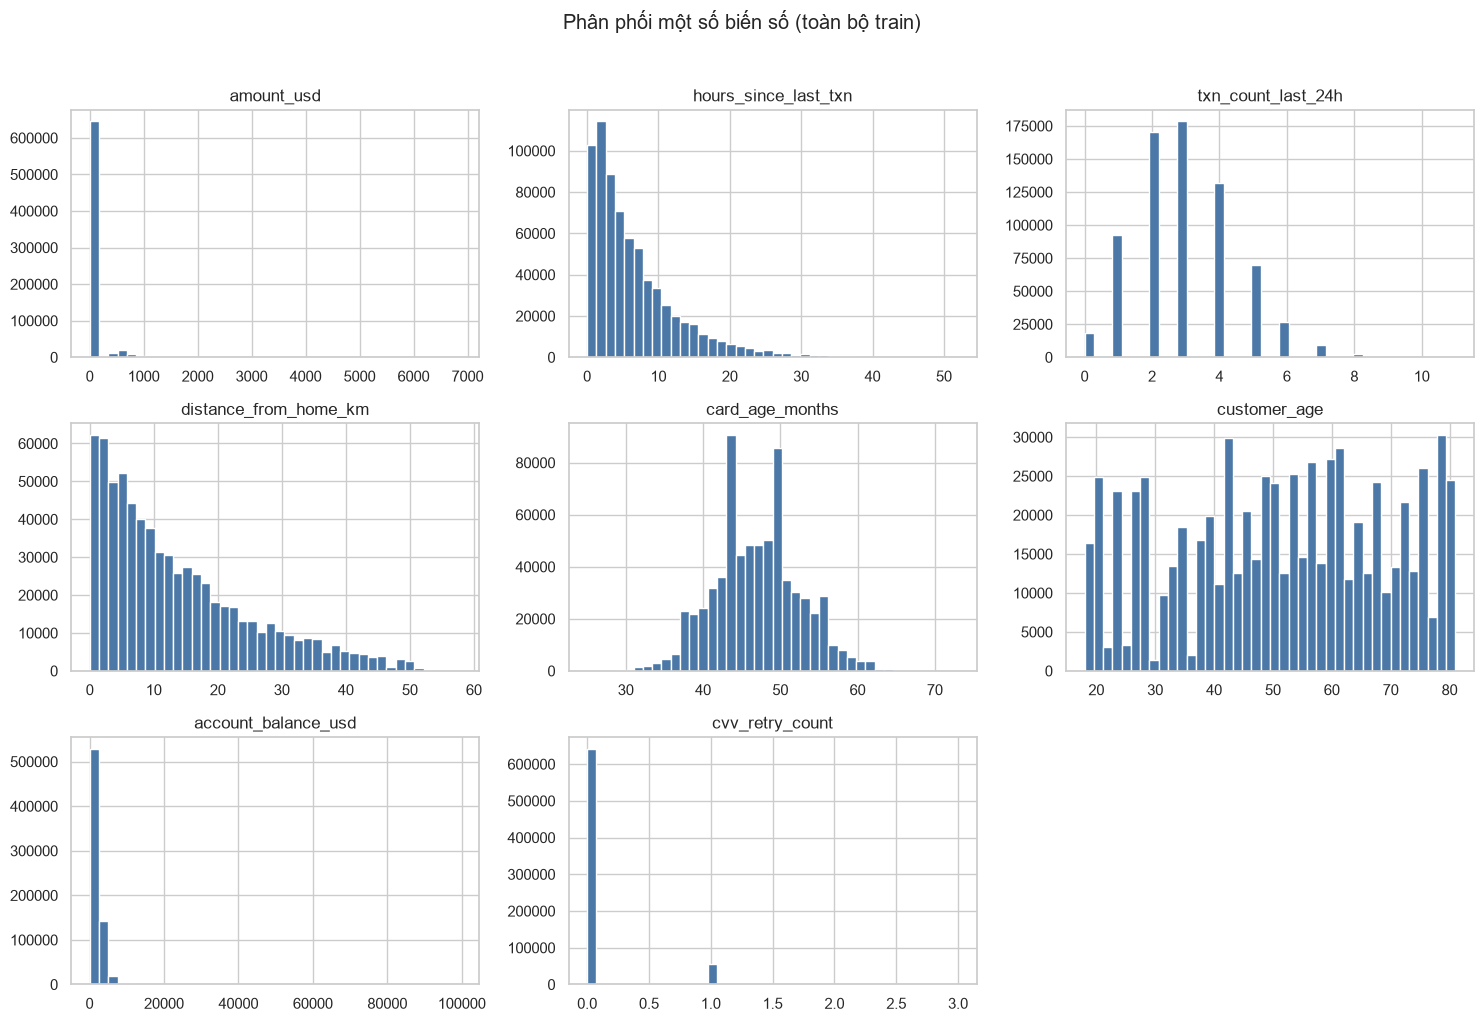

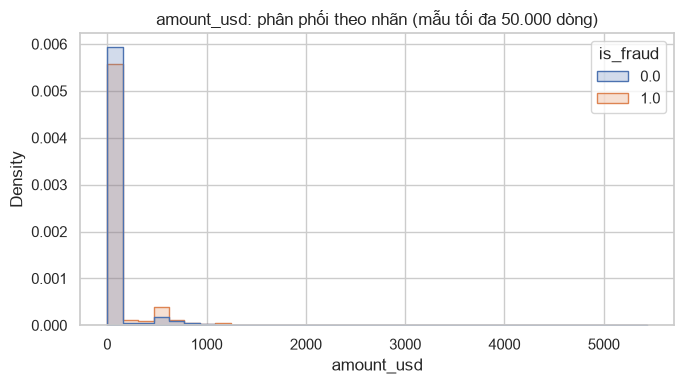

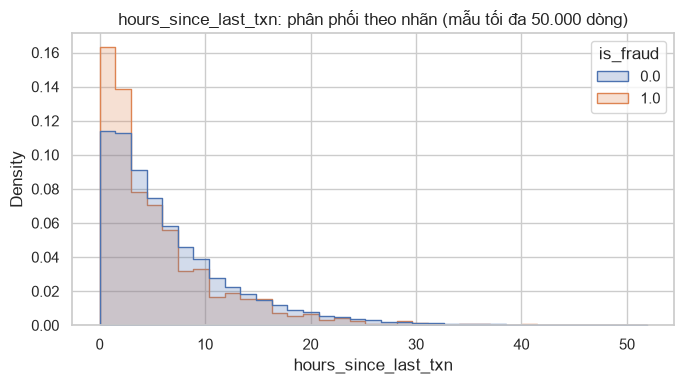

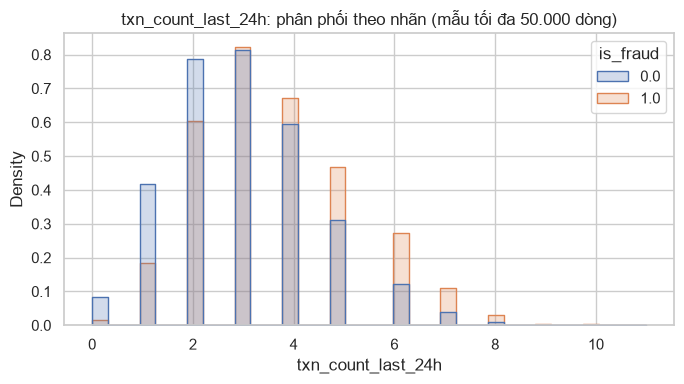

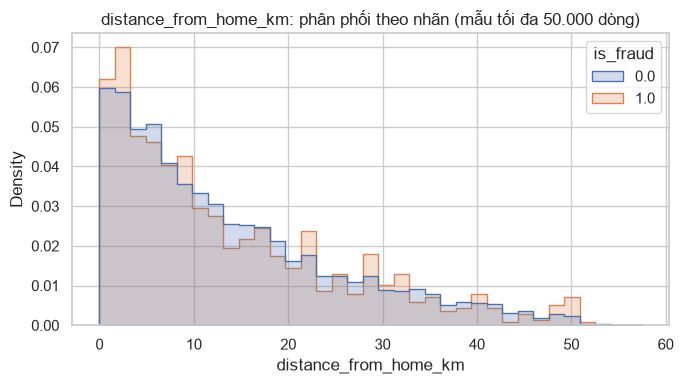

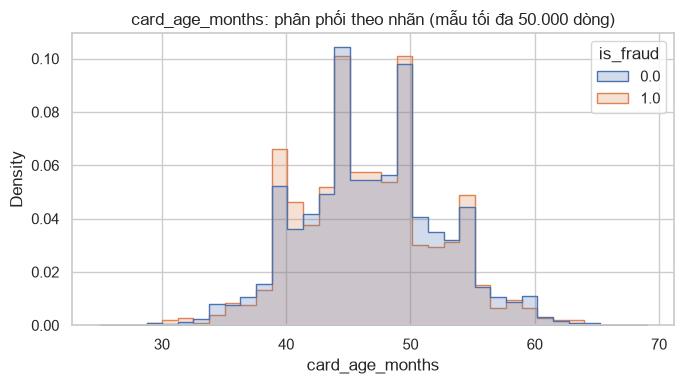

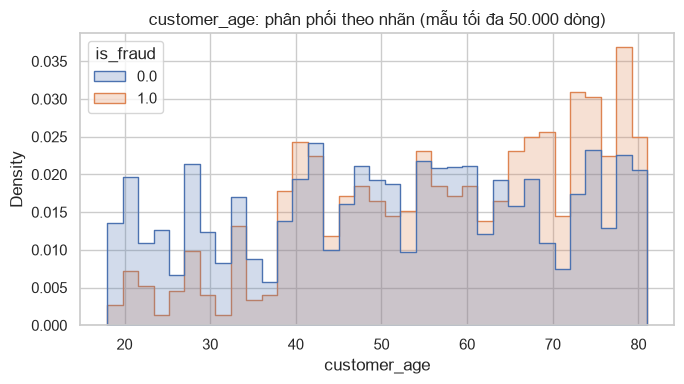

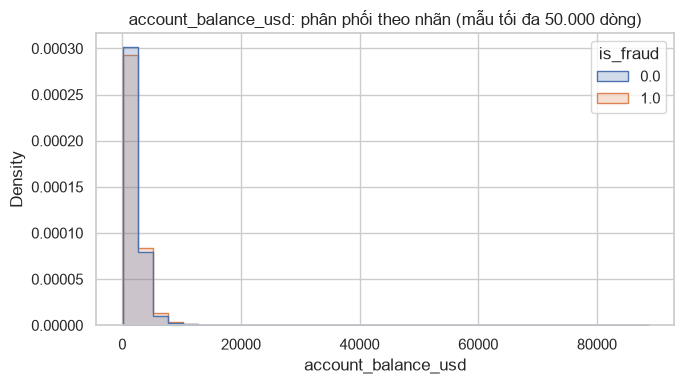

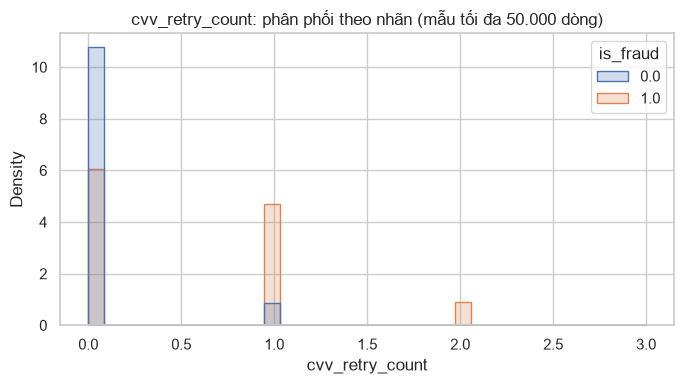

,số giao dịch,fraud rate
time_of_day_hour,,
0,25806,1.69%
1,29912,1.44%
2,26868,1.67%
3,26967,1.75%
4,27349,1.64%
5,27412,1.78%
6,27374,1.71%
7,29779,1.66%
8,27153,1.65%


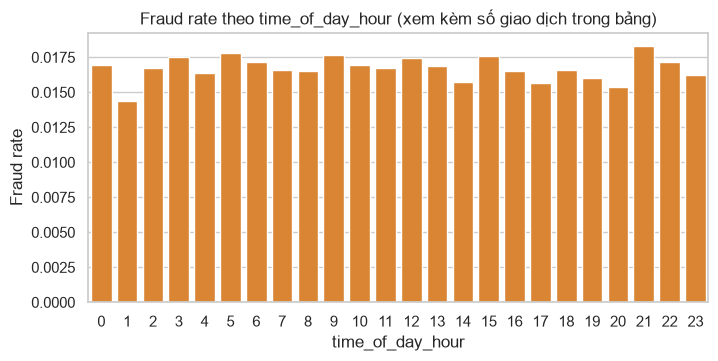

,số giao dịch,fraud rate
day_of_week,,
0,100548,1.58%
1,102288,1.66%
2,101467,1.67%
3,97261,1.64%
4,102508,1.68%
5,95271,1.68%
6,100617,1.78%


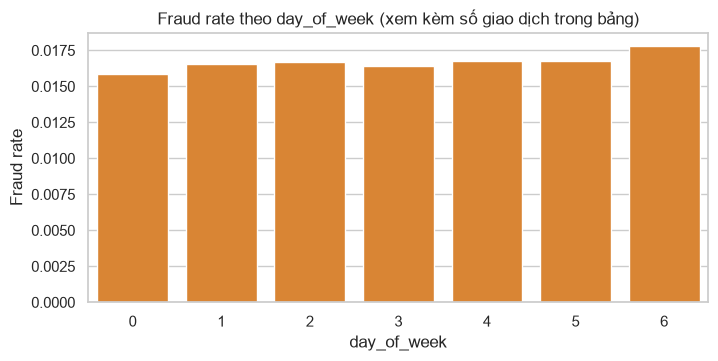

In [27]:
numeric_summary = train[numeric_features].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
numeric_summary['n_unique'] = train[numeric_features].nunique()
numeric_summary['skew'] = train[numeric_features].skew(numeric_only=True)
display(numeric_summary)

# Tách riêng biến thời gian rời rạc để không áp đặt histogram liên tục.
discrete_time = [c for c in ['time_of_day_hour', 'day_of_week'] if c in numeric_features]
continuous_features = [c for c in numeric_features if c not in discrete_time]
plot_features = continuous_features[:8]
if plot_features:
    train[plot_features].hist(bins=40, figsize=(15, 10), color='#4C78A8', edgecolor='white')
    plt.suptitle('Phân phối một số biến số (toàn bộ train)', y=1.02)
    plt.tight_layout()
    plt.show()

# So sánh nhãn trên mẫu để biểu đồ nhanh hơn; seed giúp tái tạo cùng mẫu.
plot_data = train.sample(n=min(50_000, len(train)), random_state=SEED)
for feature in plot_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=plot_data, x=feature, hue=TARGET, stat='density', common_norm=False, bins=35, element='step')
    plt.title(f'{feature}: phân phối theo nhãn (mẫu tối đa 50.000 dòng)')
    plt.tight_layout()
    plt.show()

for feature in discrete_time:
    rate = train.groupby(feature, observed=False)[TARGET].agg(['count', 'mean']).rename(columns={'count':'số giao dịch', 'mean':'fraud rate'})
    display(rate.style.format({'fraud rate':'{:.2%}'}))
    plt.figure(figsize=(8, 3.5))
    sns.barplot(x=rate.index, y=rate['fraud rate'].values, color='#F58518')
    plt.title(f'Fraud rate theo {feature} (xem kèm số giao dịch trong bảng)')
    plt.ylabel('Fraud rate')
    plt.show()

### Gợi ý ghi nhận

Sau khi xem bảng/biểu đồ, ghi bên dưới biến nào lệch phải, có đuôi dài hoặc khác biệt nhìn thấy được giữa hai nhãn. Không kết luận chỉ dựa vào hình; hãy kiểm tra thêm số mẫu và fraud rate ở bước tiếp theo.

**Ghi chú của bạn:** ...

## 6. Biến phân loại và biến đúng/sai

Fraud rate là tỷ lệ giao dịch fraud trong nhóm. Luôn xem cùng số lượng giao dịch (`count`): nhóm rất nhỏ có tỷ lệ cao nhưng chưa phải bằng chứng đáng tin. Bảng tần suất so sánh train/test giúp nhìn khác biệt phân phối.


### merchant_category


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,Crypto Exchange,5285,345.000000,6.53%,0.76,0.75
1,Electronics,48693,1501.000000,3.08%,6.96,6.96
2,Fuel,59880,741.000000,1.24%,8.55,8.62
3,Gaming,23784,1311.000000,5.51%,3.40,3.40
4,Gift Cards,9456,690.000000,7.30%,1.35,1.36
5,Groceries,142578,1585.000000,1.11%,20.37,20.45
6,Healthcare,35889,462.000000,1.29%,5.13,5.15
7,Online Retail,155097,1719.000000,1.11%,22.16,22.20
8,Restaurants,101360,1159.000000,1.14%,14.48,14.38
9,Streaming,47196,1061.000000,2.25%,6.74,6.65


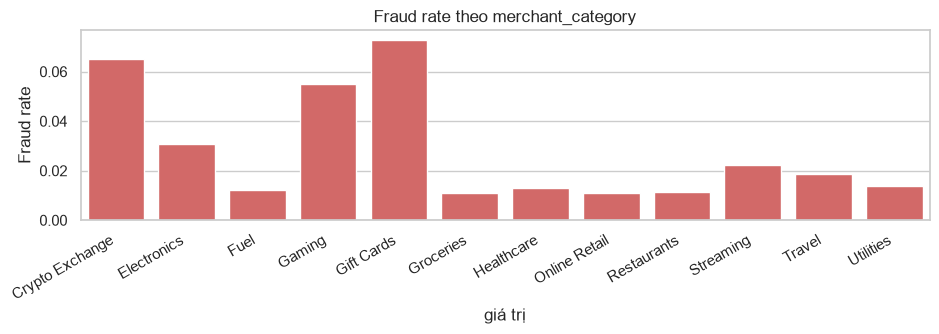


### card_type


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,Amex,45797,871.000000,1.90%,6.54,6.51
1,Discover,17235,251.000000,1.46%,2.46,2.49
2,Mastercard,254857,4084.000000,1.60%,36.41,36.36
3,RuPay,37070,623.000000,1.68%,5.30,5.26
4,Visa,345001,5860.000000,1.70%,49.29,49.38


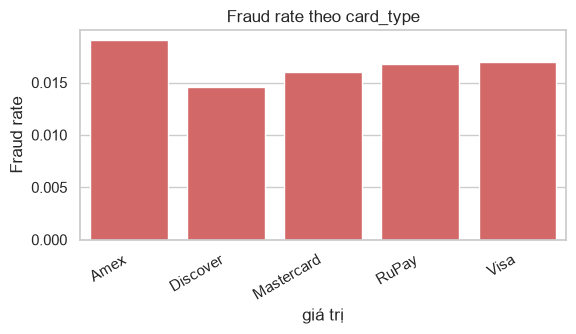


### auth_method


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,3D Secure,210036,3098.000000,1.47%,30.01,30.02
1,Biometric,93666,468.000000,0.50%,13.38,13.41
2,No Authentication,67060,4322.000000,6.44%,9.58,9.35
3,OTP,175178,2464.000000,1.41%,25.03,25.17
4,PIN,154020,1337.000000,0.87%,22.00,22.06


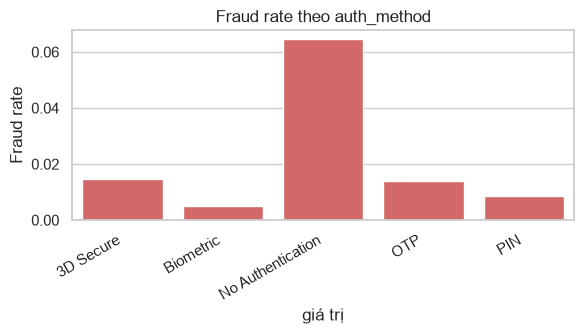


### channel


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,ATM,30220,480.000000,1.59%,4.32,4.31
1,Contactless,105620,1641.000000,1.55%,15.09,15.22
2,In-App,83716,1367.000000,1.63%,11.96,11.87
3,Online,273939,4773.000000,1.74%,39.14,39.02
4,POS,206465,3428.000000,1.66%,29.50,29.58


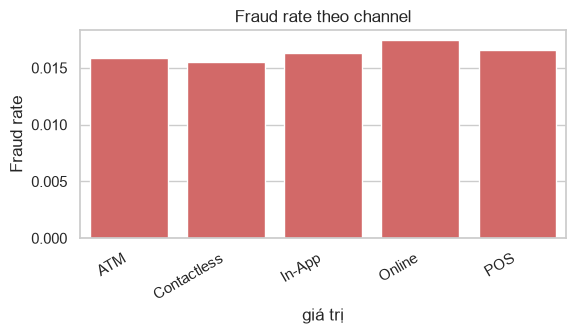


### device_type


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,ATM Machine,20877,354.000000,1.70%,2.98,3.00
1,Android Phone,237454,3824.000000,1.61%,33.92,33.83
2,Mac,33973,581.000000,1.71%,4.85,4.87
3,POS Terminal,113237,1958.000000,1.73%,16.18,16.23
4,Smart Watch,21106,359.000000,1.70%,3.02,3.07
5,Tablet,27688,471.000000,1.70%,3.96,3.97
6,Windows PC,80934,1306.000000,1.61%,11.56,11.56
7,iPhone,164691,2836.000000,1.72%,23.53,23.48


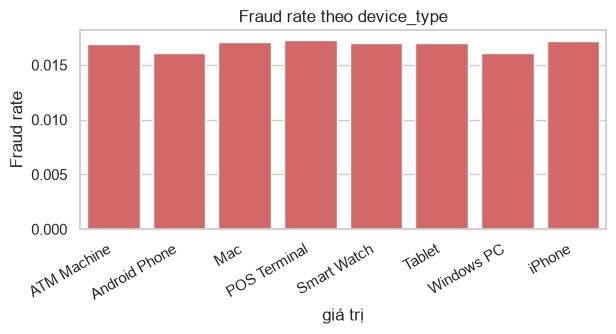


### is_foreign_transaction


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,False,687862,10168.000000,1.48%,98.27,98.26
1,True,12098,1521.000000,12.57%,1.73,1.74


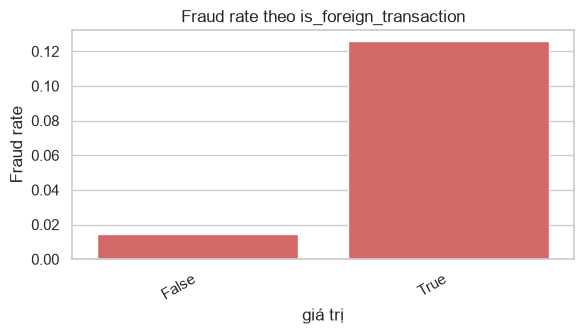


### is_new_merchant


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,False,593240,6637.000000,1.12%,84.75,84.72
1,True,106720,5052.000000,4.73%,15.25,15.28


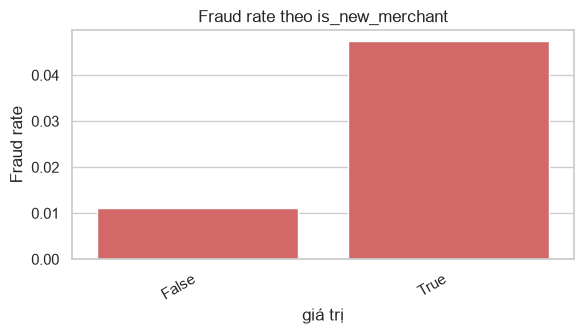


### used_vpn


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,False,676295,10139.000000,1.50%,96.62,96.70
1,True,23665,1550.000000,6.55%,3.38,3.30


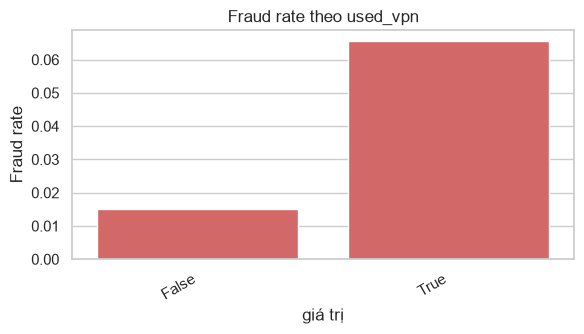


### ip_country_mismatch


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,False,688648,9823.000000,1.43%,98.38,98.40
1,True,11312,1866.000000,16.50%,1.62,1.60


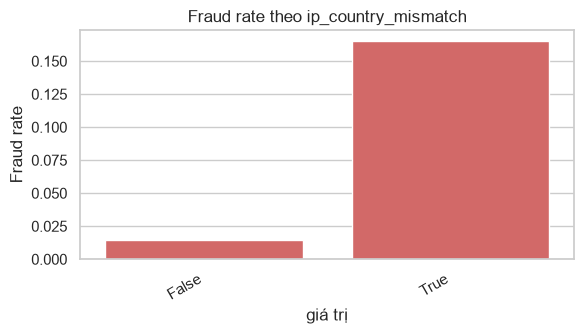


### billing_shipping_mismatch


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,False,690906,10513.000000,1.52%,98.71,98.69
1,True,9054,1176.000000,12.99%,1.29,1.31


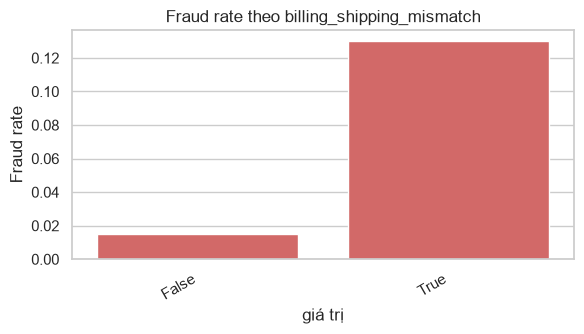


### is_ai_generated_scam_attempt


,giá trị,số giao dịch,số fraud,fraud rate,tỷ lệ train (%),tỷ lệ test (%)
0,False,697661,11339.000000,1.63%,99.67,99.66
1,True,2299,350.000000,15.22%,0.33,0.34


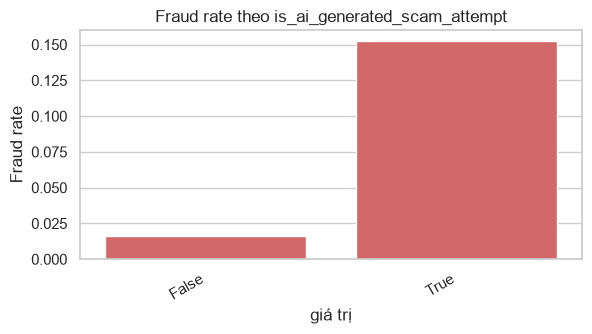

In [28]:
for feature in categorical_features + binary_features:
    summary = train.groupby(feature, dropna=False, observed=False)[TARGET].agg(['count', 'sum', 'mean']).reset_index()
    summary = summary.rename(columns={feature:'giá trị', 'count':'số giao dịch', 'sum':'số fraud', 'mean':'fraud rate'})
    summary['tỷ lệ train (%)'] = summary['số giao dịch'] / len(train) * 100
    test_frequency = test[feature].value_counts(normalize=True, dropna=False)
    summary['tỷ lệ test (%)'] = summary['giá trị'].map(test_frequency).fillna(0) * 100
    print()
    print(f'### {feature}')
    display(summary.style.format({'fraud rate':'{:.2%}', 'tỷ lệ train (%)':'{:.2f}', 'tỷ lệ test (%)':'{:.2f}'}))
    plt.figure(figsize=(max(6, min(12, summary.shape[0] * 0.8)), 3.5))
    sns.barplot(data=summary, x='giá trị', y='fraud rate', color='#E45756')
    plt.title(f'Fraud rate theo {feature}')
    plt.ylabel('Fraud rate')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

## 7. Giá trị bất thường (outlier)

Quy tắc IQR đánh dấu điểm nằm ngoài khoảng `Q1 − 1,5×IQR` đến `Q3 + 1,5×IQR`. Đây chỉ là cách phát hiện điểm cần xem xét. **Không xóa giao dịch** chỉ vì nó bị đánh dấu: giá trị hiếm có thể là tín hiệu gian lận thật.

,đặc trưng,ngưỡng dưới IQR,ngưỡng trên IQR,số điểm ngoài ngưỡng,tỷ lệ (%),fraud rate ngoài ngưỡng,số fraud ngoài ngưỡng
10,prior_disputes,0.000,0.000,101564,14.51,2.39%,2431
0,amount_usd,-25.140,84.060,70741,10.11,2.97%,2103
7,cvv_retry_count,0.000,0.000,57872,8.27,9.85%,5699
1,hours_since_last_txn,-8.510,19.810,32816,4.69,1.40%,460
6,account_balance_usd,-1690.230,5041.370,29068,4.15,1.75%,509
3,distance_from_home_km,-18.550,42.730,16770,2.40,1.68%,281
9,merchant_risk_score,1.950,67.150,13028,1.86,10.00%,1303
8,velocity_score,-10.500,47.900,4276,0.61,9.26%,396
2,txn_count_last_24h,-1.000,7.000,2704,0.39,4.47%,121
4,card_age_months,31.000,63.000,2253,0.32,1.33%,30


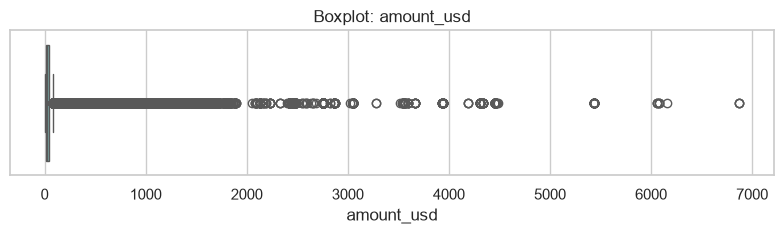

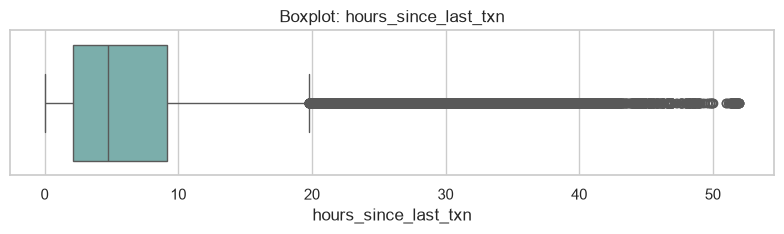

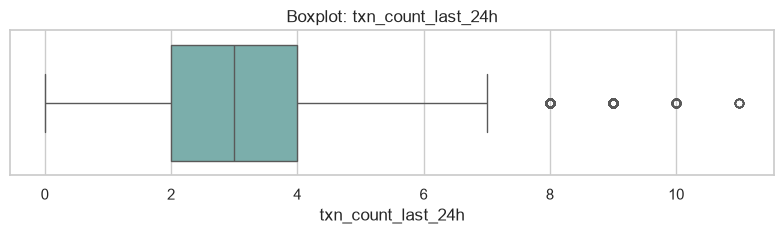

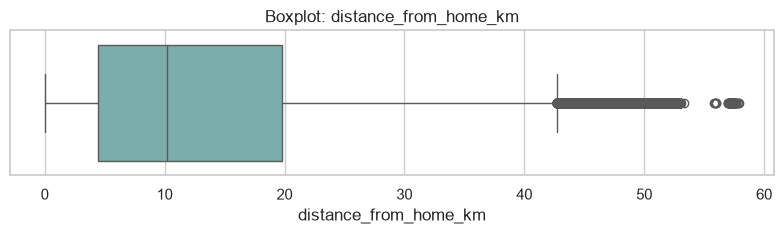

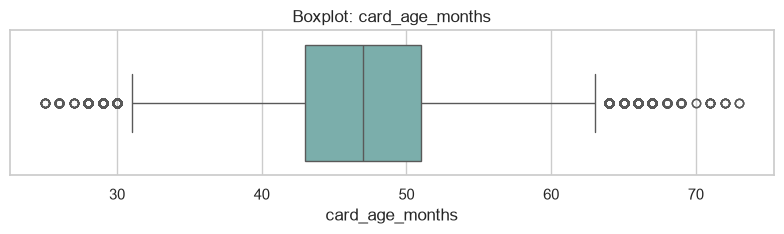

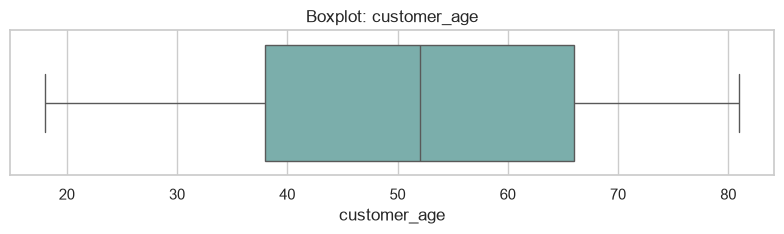

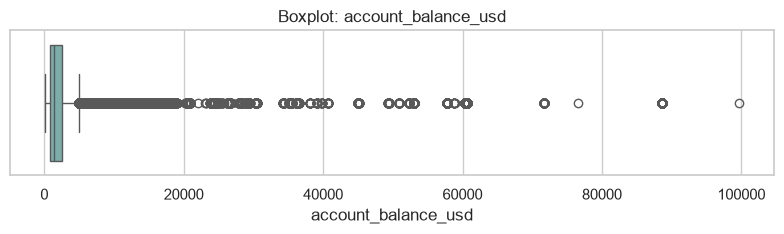

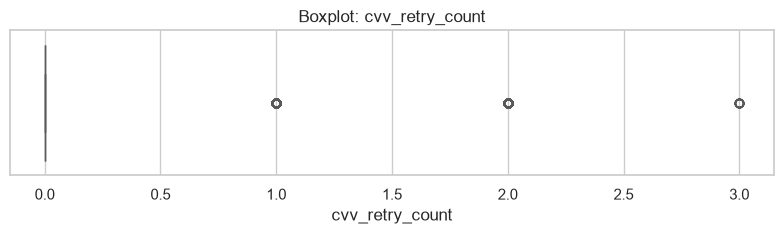

In [29]:
outlier_rows = []
for feature in continuous_features:
    q1, q3 = train[feature].quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (train[feature] < low) | (train[feature] > high)
    outlier_rows.append({
        'đặc trưng': feature, 'ngưỡng dưới IQR': low, 'ngưỡng trên IQR': high,
        'số điểm ngoài ngưỡng': int(mask.sum()), 'tỷ lệ (%)': mask.mean() * 100,
        'fraud rate ngoài ngưỡng': train.loc[mask, TARGET].mean() if mask.any() else np.nan,
        'số fraud ngoài ngưỡng': int(train.loc[mask, TARGET].sum()),
    })
outlier_summary = pd.DataFrame(outlier_rows).sort_values('tỷ lệ (%)', ascending=False)
display(outlier_summary.style.format({'ngưỡng dưới IQR':'{:.3f}', 'ngưỡng trên IQR':'{:.3f}', 'tỷ lệ (%)':'{:.2f}', 'fraud rate ngoài ngưỡng':'{:.2%}'}))

# Boxplot trên các biến đầu để dễ đọc.
for feature in continuous_features[:8]:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=train[feature], color='#72B7B2')
    plt.title(f'Boxplot: {feature}')
    plt.tight_layout()
    plt.show()

## 8. Tương quan số học

Pearson đo quan hệ tuyến tính, Spearman đo quan hệ đơn điệu theo thứ hạng. Tương quan không chứng minh quan hệ nhân quả; tương quan thấp cũng không loại trừ quan hệ phi tuyến. Đây là công cụ rà soát sơ bộ, gồm cả target để xếp hạng mối liên hệ đơn biến.

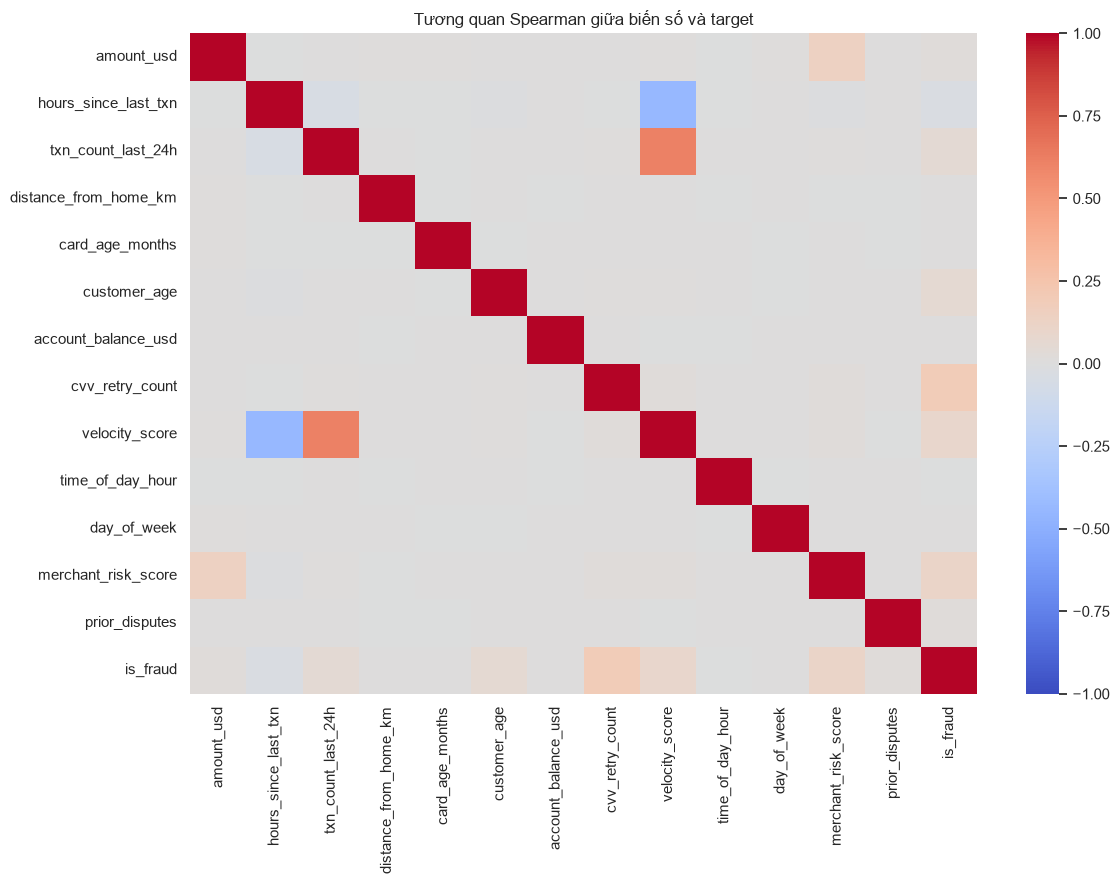

,tương quan Spearman với is_fraud
cvv_retry_count,0.193620
merchant_risk_score,0.110503
velocity_score,0.093587
customer_age,0.055374
txn_count_last_24h,0.054539
hours_since_last_txn,-0.030284
prior_disputes,0.023400
amount_usd,0.019909
day_of_week,0.003647
account_balance_usd,0.002776


In [30]:
corr_data = train[numeric_features + [TARGET]]
corr = corr_data.corr(method='spearman')
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Tương quan Spearman giữa biến số và target')
plt.tight_layout()
plt.show()

target_corr = corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
display(target_corr.rename('tương quan Spearman với is_fraud').to_frame())

## 9. Khác biệt phân phối giữa train và test

Test không có nhãn nên phần này chỉ so sánh đặc trưng đầu vào. Chênh lệch phân phối không đồng nghĩa dữ liệu sai, nhưng có thể làm kết quả validation ít đại diện cho test. KS statistic cho biến số nằm trong khoảng 0–1; càng lớn thì hai phân phối thực nghiệm càng khác. Với dữ liệu lớn, chênh lệch nhỏ cũng có thể có ý nghĩa thống kê, vì vậy hãy xem cả biểu đồ và mức chênh lệch thực tế.

,đặc trưng,train mean,test mean,train median,test median,train min,train max,test min,test max,KS statistic,KS p-value
10,day_of_week,2.981733,2.971338,3.00,3.00,0.00,6.00,0.00,6.00,0.003825,0.004277
4,card_age_months,46.862982,46.840748,47.00,47.00,25.00,73.00,24.00,72.00,0.002664,0.101382
11,merchant_risk_score,35.217648,35.217383,34.20,34.20,0.00,100.00,0.00,100.00,0.002152,0.284567
3,distance_from_home_km,13.587575,13.602890,10.22,10.27,0.00,57.93,0.00,60.47,0.001969,0.389044
6,account_balance_usd,2064.998070,2071.467998,1382.74,1388.54,58.25,99701.39,58.18,88577.93,0.001858,0.462867
9,time_of_day_hour,11.761915,11.746940,12.00,12.00,0.00,23.00,0.00,23.00,0.001568,0.679301
0,amount_usd,79.893068,79.921195,27.25,27.28,1.00,6872.69,1.00,6098.42,0.001534,0.705827
8,velocity_score,18.929445,18.938460,18.60,18.70,0.00,72.90,0.00,73.60,0.001385,0.814695
1,hours_since_last_txn,6.633734,6.640317,4.73,4.72,0.01,51.98,0.01,51.87,0.001377,0.819931
12,prior_disputes,0.152769,0.153922,0.00,0.00,0.00,4.00,0.00,4.00,0.000825,0.998805



### Chênh lệch tần suất: merchant_category


,train (%),test (%),test - train (điểm %)
merchant_category,,,
Groceries,20.369450,20.447091,0.077641
Fuel,8.554775,8.622793,0.068019
Online Retail,22.157980,22.203851,0.045870
Healthcare,5.127293,5.152275,0.024982
Gift Cards,1.350934,1.364739,0.013805
Electronics,6.956540,6.957038,0.000497
Gaming,3.397908,3.397181,-0.000727
Crypto Exchange,0.755043,0.753374,-0.001670
Travel,4.102377,4.091885,-0.010492



### Chênh lệch tần suất: card_type


,train (%),test (%),test - train (điểm %)
card_type,,,
Visa,49.288674,49.375633,0.086960
Discover,2.462284,2.488133,0.025849
Amex,6.542802,6.514014,-0.028788
RuPay,5.296017,5.258614,-0.037403
Mastercard,36.410223,36.363606,-0.046617



### Chênh lệch tần suất: auth_method


... (13 outputs left out)


### Chênh lệch tần suất: billing_shipping_mismatch


,train (%),test (%),test - train (điểm %)
billing_shipping_mismatch,,,
True,1.293502,1.308736,0.015234
False,98.706498,98.691264,-0.015234



### Chênh lệch tần suất: is_ai_generated_scam_attempt


,train (%),test (%),test - train (điểm %)
is_ai_generated_scam_attempt,,,
True,0.328447,0.343018,0.014571
False,99.671553,99.656982,-0.014571


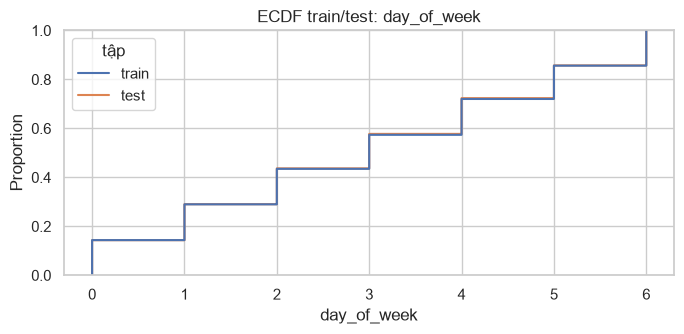

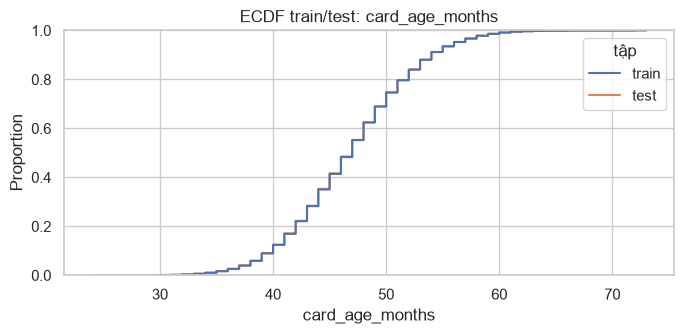

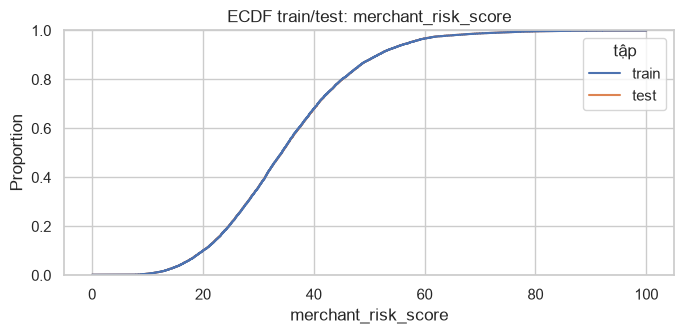

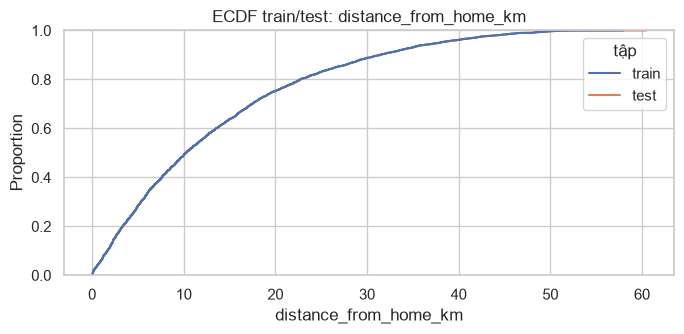

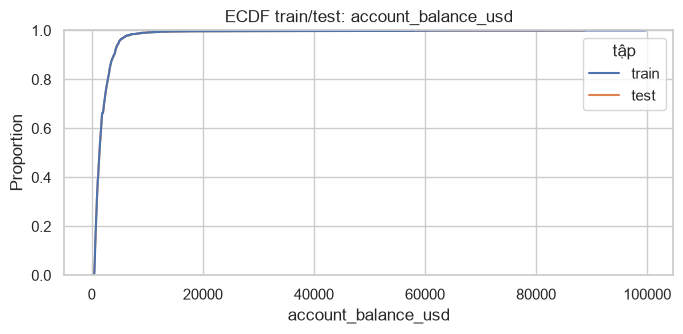

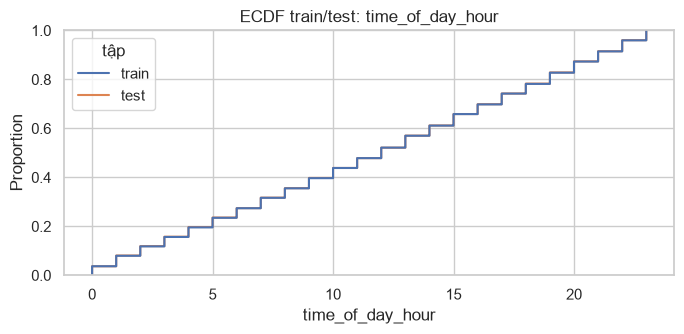

In [31]:
from scipy.stats import ks_2samp

drift_rows = []
for feature in numeric_features:
    ks = ks_2samp(train[feature], test[feature])
    drift_rows.append({
        'đặc trưng': feature, 'train mean': train[feature].mean(), 'test mean': test[feature].mean(),
        'train median': train[feature].median(), 'test median': test[feature].median(),
        'train min': train[feature].min(), 'train max': train[feature].max(),
        'test min': test[feature].min(), 'test max': test[feature].max(),
        'KS statistic': ks.statistic, 'KS p-value': ks.pvalue,
    })
numeric_drift = pd.DataFrame(drift_rows).sort_values('KS statistic', ascending=False)
display(numeric_drift)

# Bảng chênh lệch tỷ lệ category: giá trị dương nghĩa là test có tỷ lệ cao hơn train.
for feature in categorical_features + binary_features:
    train_freq = train[feature].value_counts(normalize=True, dropna=False)
    test_freq = test[feature].value_counts(normalize=True, dropna=False)
    freq = pd.concat([train_freq.rename('train (%)'), test_freq.rename('test (%)')], axis=1).fillna(0) * 100
    freq['test - train (điểm %)'] = freq['test (%)'] - freq['train (%)']
    print()
    print(f'### Chênh lệch tần suất: {feature}')
    display(freq.sort_values('test - train (điểm %)', ascending=False))

# So sánh biểu đồ cho một số biến số có KS lớn nhất.
for feature in numeric_drift.head(6)['đặc trưng']:
    combined = pd.concat([train[[feature]].assign(tập='train'), test[[feature]].assign(tập='test')], ignore_index=True)
    plt.figure(figsize=(7, 3.5))
    sns.ecdfplot(data=combined, x=feature, hue='tập')
    plt.title(f'ECDF train/test: {feature}')
    plt.tight_layout()
    plt.show()

## 10. Rà soát nguy cơ rò rỉ nhãn (leakage)

EDA không thể xác nhận thời điểm hoặc công thức tạo ra feature. Hãy hỏi người cung cấp dữ liệu/nhóm: giá trị này có sẵn tại lúc giao dịch được chấm điểm không, hay chỉ được tạo sau khi fraud đã được xác nhận?

Các cột cần tìm hiểu nguồn gốc kỹ hơn theo tên: `merchant_risk_score`, `is_ai_generated_scam_attempt`. Tên cột chỉ tạo ra câu hỏi, **không đủ để kết luận leakage**. Không loại cột nếu chưa có căn cứ; ghi rõ phần chưa xác minh.

In [32]:
leakage_review = pd.DataFrame([
    {'đặc trưng cần hỏi': 'merchant_risk_score', 'câu hỏi': 'Điểm rủi ro được tính trước hay sau khi giao dịch được xác minh fraud?', 'trạng thái': 'Cần xác minh với nguồn dữ liệu'},
    {'đặc trưng cần hỏi': 'is_ai_generated_scam_attempt', 'câu hỏi': 'Cờ này có sẵn tại thời điểm dự đoán hay được gán sau điều tra?', 'trạng thái': 'Cần xác minh với nguồn dữ liệu'},
    {'đặc trưng cần hỏi': 'Các đặc trưng còn lại', 'câu hỏi': 'Có sử dụng trực tiếp/gián tiếp nhãn fraud hoặc thông tin hậu nghiệm không?', 'trạng thái': 'Cần xác minh theo tài liệu tạo dữ liệu'},
])
display(leakage_review)

,đặc trưng cần hỏi,câu hỏi,trạng thái
0,merchant_risk_score,Điểm rủi ro được tính trước hay sau khi giao d...,Cần xác minh với nguồn dữ liệu
1,is_ai_generated_scam_attempt,Cờ này có sẵn tại thời điểm dự đoán hay được g...,Cần xác minh với nguồn dữ liệu
2,Các đặc trưng còn lại,Có sử dụng trực tiếp/gián tiếp nhãn fraud hoặc...,Cần xác minh theo tài liệu tạo dữ liệu


## 11. Kết luận EDA và validation protocol

### Kết luận EDA

- Train có 699.960 giao dịch và test có 299.984 giao dịch. Không phát hiện missing value, dòng trùng hoàn toàn, ID trùng hoặc ID giao nhau giữa hai tập. `id` là khóa định danh, không dùng làm feature.
- Có 24 feature: 13 biến số, 5 biến phân loại và 6 biến đúng/sai. Target có 11.689 fraud (1,669953%), nên lớp fraud hiếm mạnh; accuracy không phù hợp làm metric chính.
- Fraud rate nổi bật theo nhóm gồm `merchant_category=Gift Cards` (7,30%; 690/9.456), `Crypto Exchange` (6,53%; 345/5.285), `Gaming` (5,51%; 1.311/23.784) và `auth_method=No Authentication` (6,44%; 4.322/67.060). Một số cờ cũng có fraud rate cao: `ip_country_mismatch=True` (16,50%; 1.866/11.312), `billing_shipping_mismatch=True` (12,99%; 1.176/9.054), `is_foreign_transaction=True` (12,57%; 1.521/12.098), `is_ai_generated_scam_attempt=True` (15,22%; 350/2.299). Đây là các liên hệ mô tả; chúng không chứng minh quan hệ nhân quả hay khả năng dự đoán độc lập.
- Quy tắc IQR đánh dấu một số nhóm đuôi, ví dụ `amount_usd` 70.741 dòng (fraud rate 2,97%), `cvv_retry_count` 57.872 dòng (9,85%), và `merchant_risk_score` 13.028 dòng (10,00%). Với `prior_disputes`, ngưỡng trên IQR bằng 0 do phần lớn giá trị là 0 nên quy tắc đánh dấu mọi giá trị dương. Không xóa outlier chỉ vì quy tắc này.
- Tương quan Spearman đơn biến lớn nhất với target là `cvv_retry_count` (0,194), `merchant_risk_score` (0,111) và `velocity_score` (0,094); các giá trị này không thể hiện quan hệ nhân quả. Phân phối train/test nhìn chung sát nhau; KS lớn nhất là `day_of_week` (0,0038), một chênh lệch nhỏ.
- Chưa xác minh thời điểm tạo/khả dụng của `merchant_risk_score` và `is_ai_generated_scam_attempt`. Cần hỏi nguồn dữ liệu trước khi kết luận về leakage; hiện không loại hai feature này chỉ dựa vào tên.

### Validation đã chốt

Dùng stratified holdout 80/20, seed 42 và artifact ID cố định `experiments/validation/validation_ids_seed42.csv`. Validation có 139.992 dòng (2.338 fraud); train có 559.968 dòng (9.351 fraud). Split ID: `stratified-holdout-v1-seed42-val20-34abc885ee94`. Chi tiết metric, chống leakage và cách nạp split nằm trong `docs/02_VALIDATION_PROTOCOL.md`. Mọi mô hình ML/DL phải dùng đúng split này; không dùng test để chọn mô hình.

### Checklist bàn giao

- [x] Notebook đã chạy từ đầu đến cuối, gồm 5 biến phân loại sau khi nhận diện kiểu string.
- [x] Đã khảo sát biến số, categorical, binary, outlier, tương quan, drift và nguy cơ leakage.
- [x] Đã chốt split chung, seed, metric và artifact ID validation.
- [x] Không dùng `id` làm feature, không tự động xóa outlier và không sửa CSV gốc.
- [ ] Xác minh với chủ sở hữu dữ liệu thời điểm tạo của các feature có nghi vấn leakage.
